In [ ]:
!pip install -q pycocotools pandas matplotlib pillow requests

In [ ]:
import os
import json
import requests
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter, defaultdict
from matplotlib.patches import Rectangle
from pycocotools.coco import COCO

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
DATASET_DIR = "/content/VisionPort_COCO"

ANNOTATION_DIR = os.path.join(
    DATASET_DIR, "annotations"
)

IMAGE_DIR = os.path.join(
    DATASET_DIR, "traffic_images"
)

os.makedirs(ANNOTATION_DIR, exist_ok=True)
os.makedirs(IMAGE_DIR, exist_ok=True)

print("Dataset directories created successfully!")
print("Dataset location:", DATASET_DIR)

Dataset directories created successfully!
Dataset location: /content/VisionPort_COCO


In [ ]:
annotation_url = (
    "http://images.cocodataset.org/annotations/"
    "annotations_trainval2017.zip"
)

zip_path = os.path.join(
    DATASET_DIR, "annotations.zip"
)

if not os.path.exists(zip_path):

    print("Downloading COCO annotations...")

    response = requests.get(
        annotation_url,
        stream=True,
        timeout=120
    )

    response.raise_for_status()

    with open(zip_path, "wb") as file:

        for chunk in response.iter_content(
            chunk_size=1024 * 1024
        ):

            if chunk:
                file.write(chunk)

    print("Download completed!")

else:
    print("Annotation ZIP already downloaded!")

print("Extracting annotations...")

import zipfile

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(DATASET_DIR)

print("COCO annotations extracted successfully!")

Download completed!
Extracting annotations...
COCO annotations extracted successfully!


In [ ]:
annotation_file = os.path.join(
    ANNOTATION_DIR,
    "instances_val2017.json"
)

coco = COCO(annotation_file)

print("COCO dataset loaded successfully!")

print("Total Images:", len(coco.imgs))
print("Total Annotations:", len(coco.anns))
print("Total Categories:", len(coco.cats))

loading annotations into memory...
Done (t=0.59s)
creating index...
index created!
COCO dataset loaded successfully!
Total Images: 5000
Total Annotations: 36781
Total Categories: 80


In [ ]:
categories = coco.loadCats(
    coco.getCatIds()
)

category_data = []

for category in categories:

    category_data.append({
        "Category ID": category["id"],
        "Category Name": category["name"],
        "Supercategory": category["supercategory"]
    })

category_df = pd.DataFrame(category_data)

print("COCO Dataset Categories")

display(category_df)

print("Total Categories:", len(category_df))

COCO Dataset Categories


,Category ID,Category Name,Supercategory
0,1,person,person
1,2,bicycle,vehicle
2,3,car,vehicle
3,4,motorcycle,vehicle
4,5,airplane,vehicle
...,...,...,...
75,86,vase,indoor
76,87,scissors,indoor
77,88,teddy bear,indoor
78,89,hair drier,indoor


Total Categories: 80


In [ ]:
traffic_categories = [
    "person",
    "bicycle",
    "car",
    "motorcycle",
    "bus",
    "truck"
]

traffic_category_ids = coco.getCatIds(
    catNms=traffic_categories
)

print("Selected Traffic Categories")
print("--------------------------------")

for category_id in traffic_category_ids:

    category = coco.loadCats(
        [category_id]
    )[0]

    print(
        "ID:", category["id"],
        "| Name:", category["name"]
    )

Selected Traffic Categories
--------------------------------
ID: 1 | Name: person
ID: 2 | Name: bicycle
ID: 3 | Name: car
ID: 4 | Name: motorcycle
ID: 6 | Name: bus
ID: 8 | Name: truck


In [ ]:
traffic_annotation_ids = coco.getAnnIds(
    catIds=traffic_category_ids
)

traffic_annotations = coco.loadAnns(
    traffic_annotation_ids
)

object_counts = Counter()

for annotation in traffic_annotations:

    category_id = annotation["category_id"]

    category = coco.loadCats(
        [category_id]
    )[0]

    object_counts[category["name"]] += 1

print("Traffic Object Annotation Counts")
print("--------------------------------")

for category, count in object_counts.items():

    print(category, ":", count)

print("--------------------------------")
print(
    "Total Traffic Objects:",
    sum(object_counts.values())
)

Traffic Object Annotation Counts
--------------------------------
bicycle : 316
car : 1932
motorcycle : 371
bus : 285
person : 11004
truck : 415
--------------------------------
Total Traffic Objects: 14323


In [ ]:
image_annotations = defaultdict(list)

for annotation in traffic_annotations:

    image_id = annotation["image_id"]

    image_annotations[image_id].append(
        annotation
    )

traffic_image_ids = list(
    image_annotations.keys()
)

print(
    "Images containing traffic objects:",
    len(traffic_image_ids)
)

# Select up to six images with the most traffic annotations
selected_image_ids = sorted(
    traffic_image_ids,
    key=lambda image_id: len(
        image_annotations[image_id]
    ),
    reverse=True
)[:6]

print("Selected Image IDs:")
print(selected_image_ids)

Images containing traffic objects: 2968
Selected Image IDs:
[210273, 254814, 490936, 165681, 343561, 19109]


In [ ]:
image_info = {}

for image_id in selected_image_ids:

    info = coco.loadImgs([image_id])[0]

    file_name = info["file_name"]

    image_url = (
        "http://images.cocodataset.org/val2017/"
        + file_name
    )

    image_path = os.path.join(
        IMAGE_DIR,
        file_name
    )

    if not os.path.exists(image_path):

        response = requests.get(
            image_url,
            timeout=60
        )

        response.raise_for_status()

        with open(image_path, "wb") as file:
            file.write(response.content)

    image_info[image_id] = {
        "path": image_path,
        "file_name": file_name,
        "width": info["width"],
        "height": info["height"]
    }

    print("Image ready:", file_name)

print("All selected images are ready!")

Image ready: 000000210273.jpg
Image ready: 000000254814.jpg
Image ready: 000000490936.jpg
Image ready: 000000165681.jpg
Image ready: 000000343561.jpg
Image ready: 000000019109.jpg
All selected images are ready!


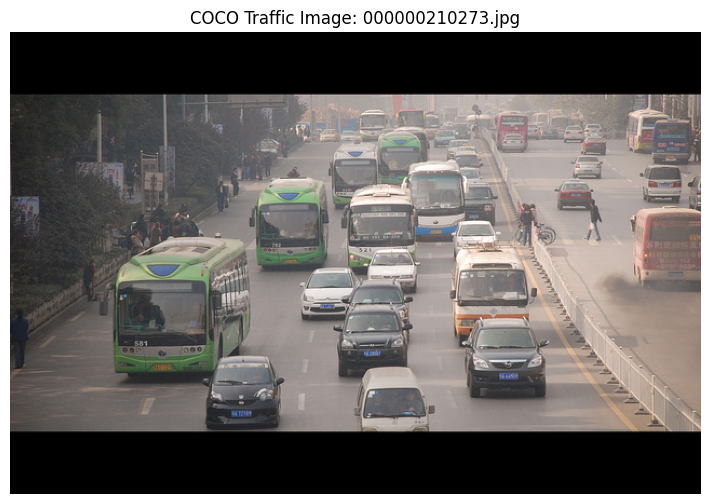

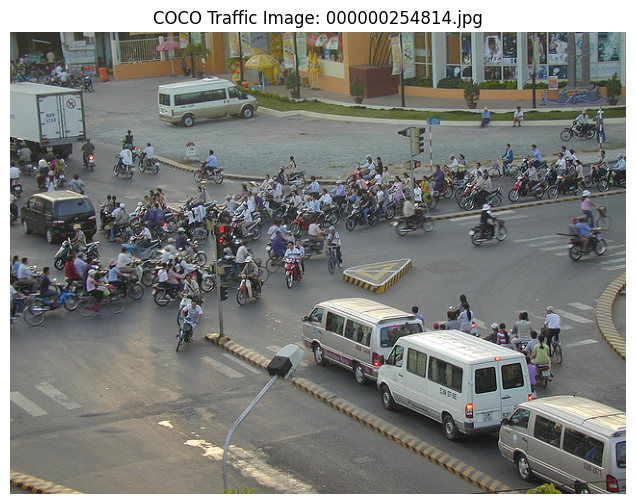

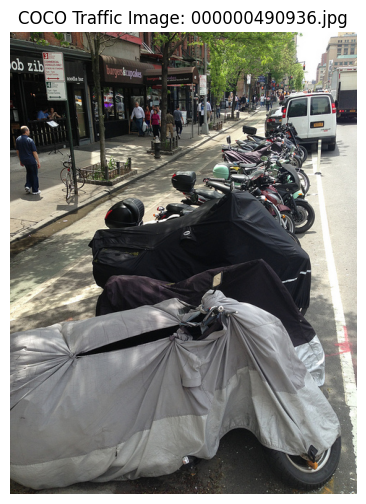

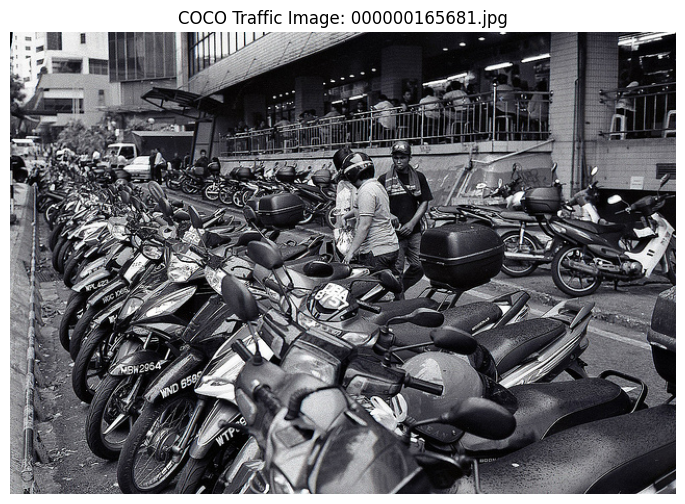

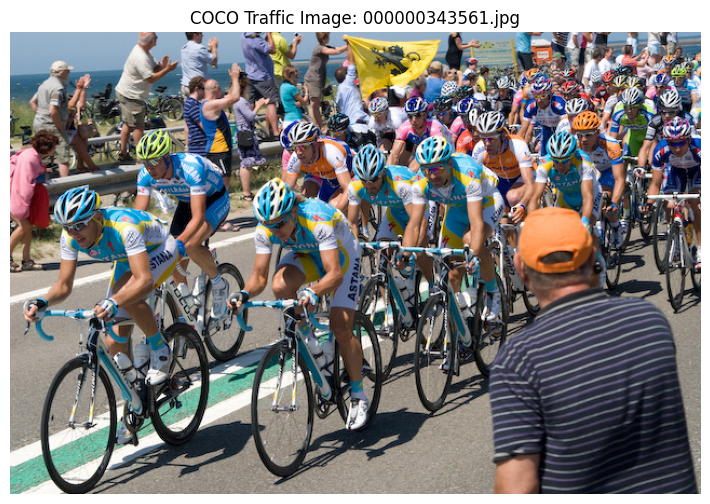

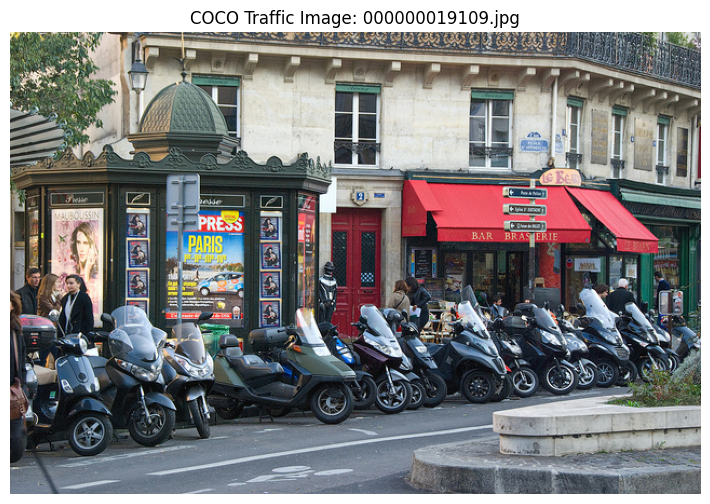

In [ ]:
for image_id in selected_image_ids:

    image_path = image_info[image_id]["path"]

    image = Image.open(
        image_path
    ).convert("RGB")

    plt.figure(figsize=(10, 6))

    plt.imshow(image)

    plt.title(
        "COCO Traffic Image: "
        + image_info[image_id]["file_name"]
    )

    plt.axis("off")

    plt.show()

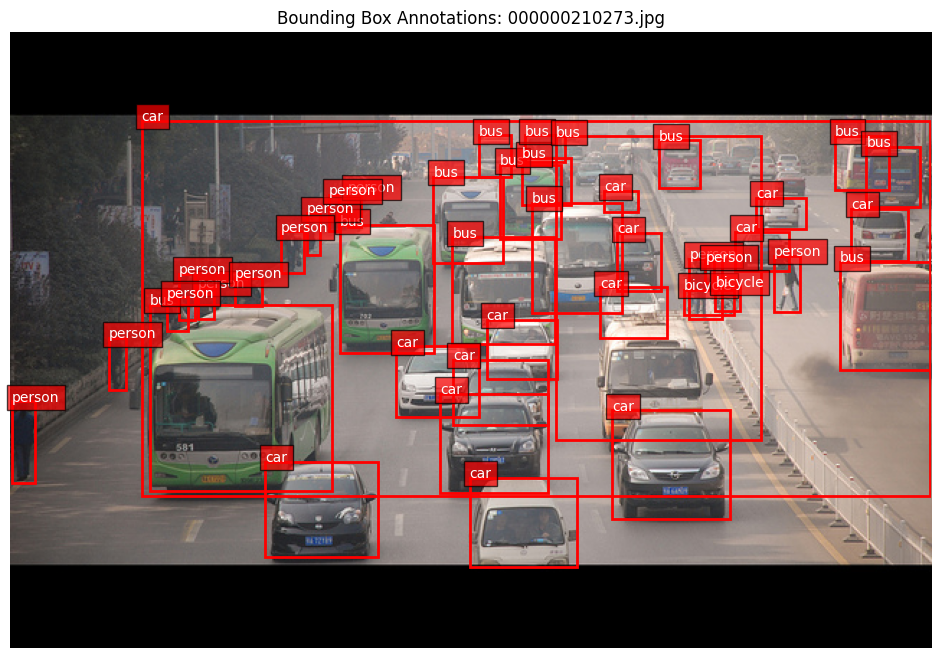

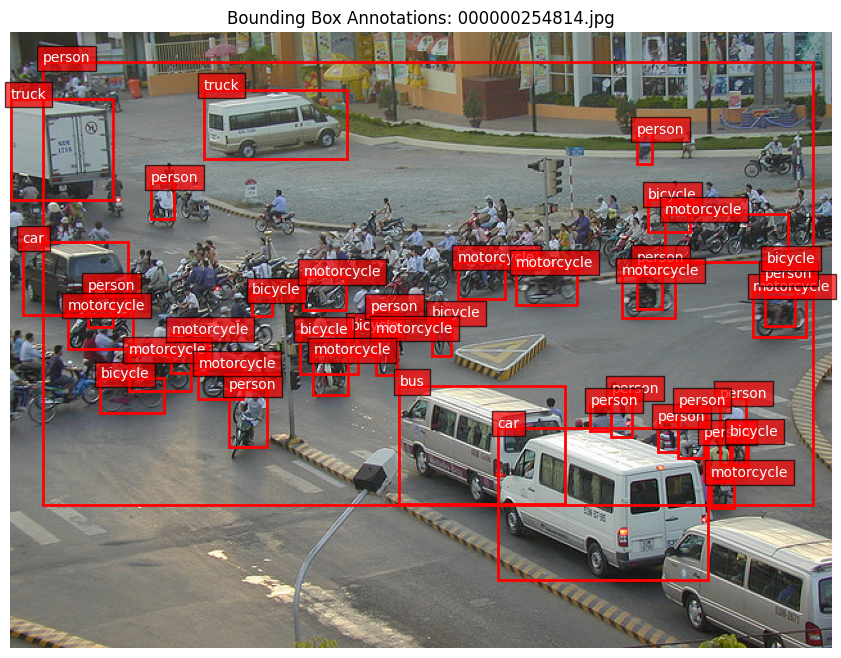

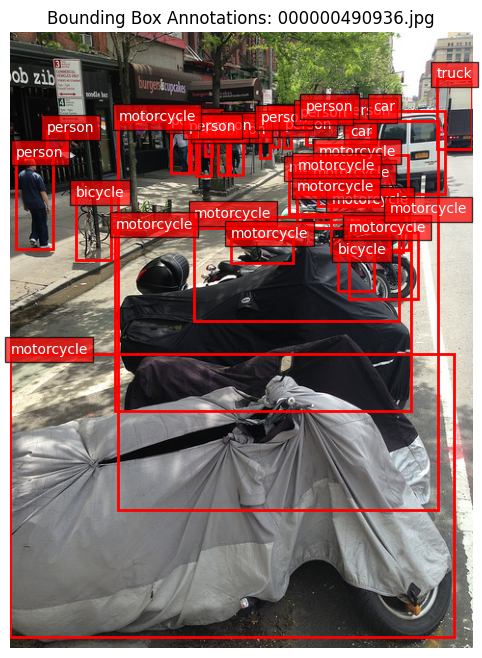

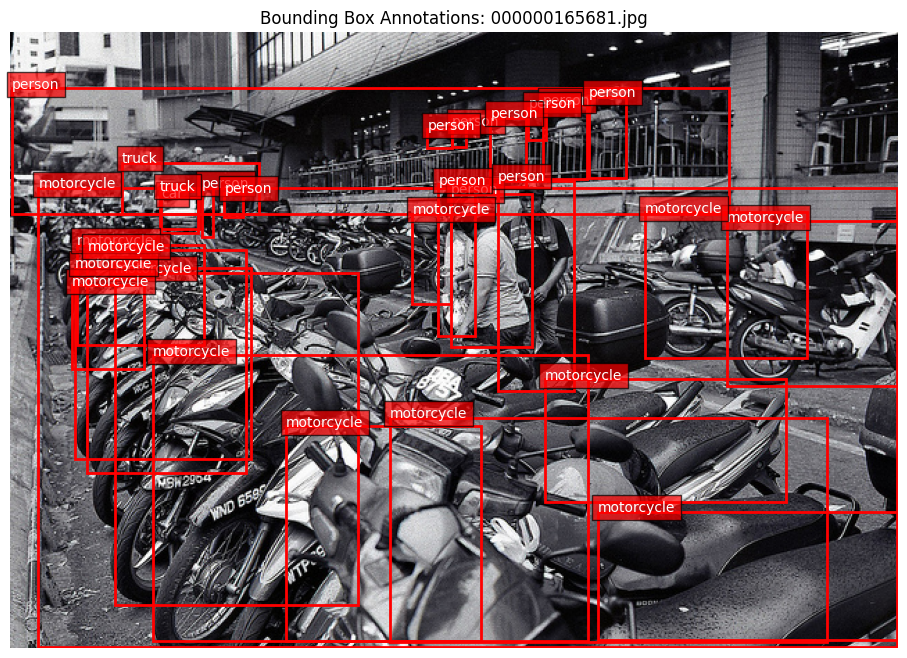

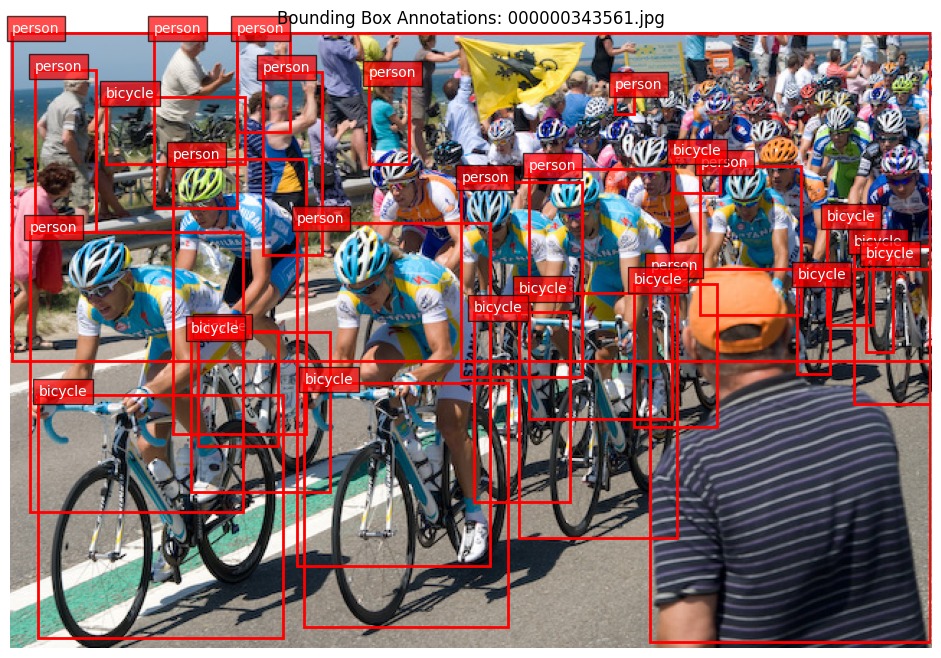

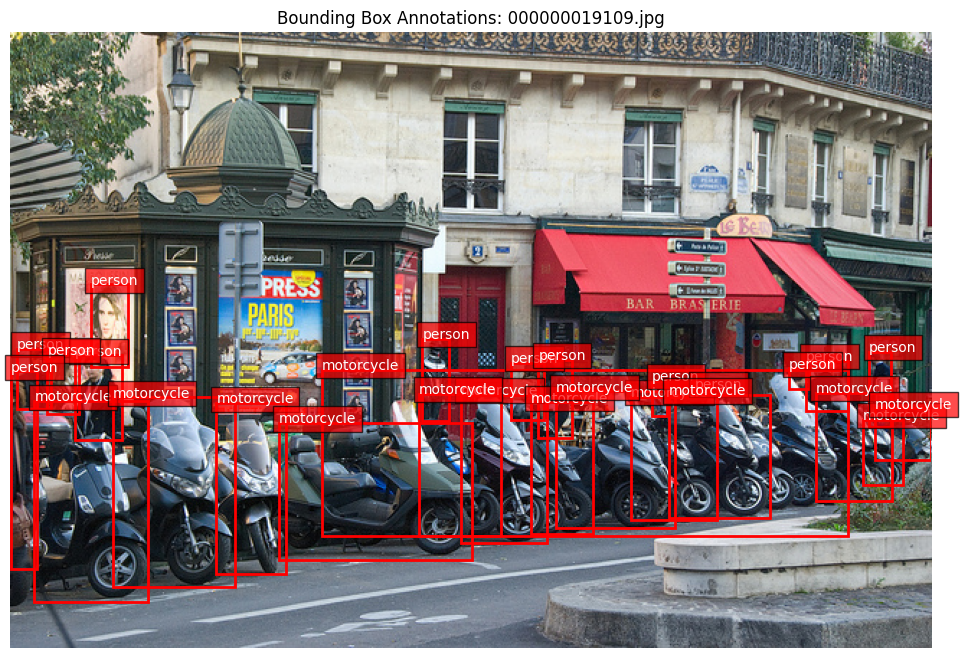

In [ ]:
for image_id in selected_image_ids:

    image_path = image_info[image_id]["path"]

    image = Image.open(
        image_path
    ).convert("RGB")

    fig, ax = plt.subplots(
        figsize=(12, 8)
    )

    ax.imshow(image)

    annotations = image_annotations[image_id]

    for annotation in annotations:

        category_id = annotation["category_id"]

        category = coco.loadCats(
            [category_id]
        )[0]

        label = category["name"]

        # COCO format: [x, y, width, height]
        x, y, width, height = annotation["bbox"]

        rectangle = Rectangle(
            (x, y),
            width,
            height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rectangle)

        ax.text(
            x,
            y,
            label,
            color="white",
            fontsize=10,
            bbox=dict(
                facecolor="red",
                alpha=0.7
            )
        )

    ax.set_title(
        "Bounding Box Annotations: "
        + image_info[image_id]["file_name"]
    )

    ax.axis("off")

    plt.show()

In [ ]:
annotation_details = []

for image_id in selected_image_ids:

    for annotation in image_annotations[image_id]:

        category_id = annotation["category_id"]

        category = coco.loadCats(
            [category_id]
        )[0]

        x, y, width, height = annotation["bbox"]

        annotation_details.append({

            "Image ID": image_id,

            "Annotation ID": annotation["id"],

            "Category": category["name"],

            "X": x,

            "Y": y,

            "Width": width,

            "Height": height,

            "Area": annotation["area"],

            "Is Crowd": annotation["iscrowd"]
        })

annotation_df = pd.DataFrame(
    annotation_details
)

display(annotation_df)

print(
    "Total displayed annotations:",
    len(annotation_df)
)

,Image ID,Annotation ID,Category,X,Y,Width,Height,Area,Is Crowd
0,210273,127213,bicycle,467.67,178.52,34.79,17.27,192.48605,0
1,210273,164381,bus,96.61,189.12,126.57,129.46,14253.49750,0
2,210273,166669,bus,228.91,133.93,65.40,88.49,5047.44300,0
3,210273,168737,bus,576.16,159.42,63.84,74.94,4316.53800,0
4,210273,169222,bus,293.68,100.00,48.14,59.87,2065.02490,0
...,...,...,...,...,...,...,...,...,...
193,19109,1791159,motorcycle,600.40,260.87,39.05,36.30,678.71500,0
194,19109,1791194,motorcycle,283.79,250.77,56.73,98.94,1589.22940,0
195,19109,2025750,person,55.53,174.84,26.29,57.72,1149.92285,0
196,19109,2048655,motorcycle,457.22,251.68,70.06,85.22,3163.52635,0


Total displayed annotations: 198


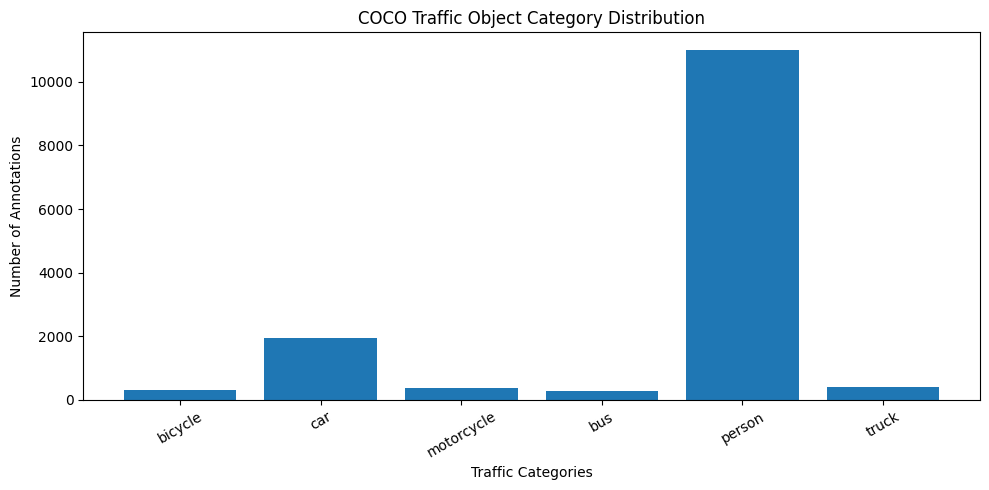

In [ ]:
category_names = list(
    object_counts.keys()
)

category_values = list(
    object_counts.values()
)

plt.figure(figsize=(10, 5))

plt.bar(
    category_names,
    category_values
)

plt.title(
    "COCO Traffic Object Category Distribution"
)

plt.xlabel("Traffic Categories")

plt.ylabel("Number of Annotations")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

In [ ]:
sample_annotation = traffic_annotations[0]

category_id = sample_annotation["category_id"]

category_name = coco.loadCats(
    [category_id]
)[0]["name"]

x, y, width, height = sample_annotation["bbox"]

print("BOUNDING BOX DETAILS")
print("--------------------")

print(
    "Annotation ID:",
    sample_annotation["id"]
)

print(
    "Image ID:",
    sample_annotation["image_id"]
)

print(
    "Object Category:",
    category_name
)

print("\nCOCO Format: [x, y, width, height]")

print("X:", x)
print("Y:", y)
print("Width:", width)
print("Height:", height)

print("\nCalculated Coordinates")

print("Top-left:", (x, y))

print(
    "Bottom-right:",
    (x + width, y + height)
)

BOUNDING BOX DETAILS
--------------------
Annotation ID: 124742
Image ID: 45596
Object Category: bicycle

COCO Format: [x, y, width, height]
X: 161.52
Y: 507.18
Width: 46.45
Height: 19.16

Calculated Coordinates
Top-left: (161.52, 507.18)
Bottom-right: (207.97000000000003, 526.34)


In [ ]:
output_csv = (
    "/content/VisionPort_COCO_Annotations.csv"
)

annotation_df.to_csv(
    output_csv,
    index=False
)

print("Annotation report saved successfully!")

print("File:", output_csv)

Annotation report saved successfully!
File: /content/VisionPort_COCO_Annotations.csv


In [ ]:
from google.colab import files

files.download(
    output_csv
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>